<a href="https://colab.research.google.com/github/yaojun1498871/DATA-555-Project-2-/blob/main/Project_2_DATA_555.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
!pip install ucimlrepo

In [19]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch dataset using its UCI ID
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# Extract the features (X) and targets (y) as pandas dataframes
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# Combine them into a single dataframe for Exploratory Data Analysis (EDA)
df = pd.concat([X, y], axis=1)

# View the first 5 rows to confirm it imported correctly
df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Map 'M' (Malignant) to 1 and 'B' (Benign) to 0 in both df and y
df['Diagnosis'] = df['Diagnosis'].map({'M': 1, 'B': 0})
y = y['Diagnosis'].map({'M': 1, 'B': 0})

# Perform a quality check for missing values
print("Total missing values in dataset:", df.isnull().sum().sum())

Total missing values in dataset: 0


In [21]:
# Check data types and verify non-null counts for all columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

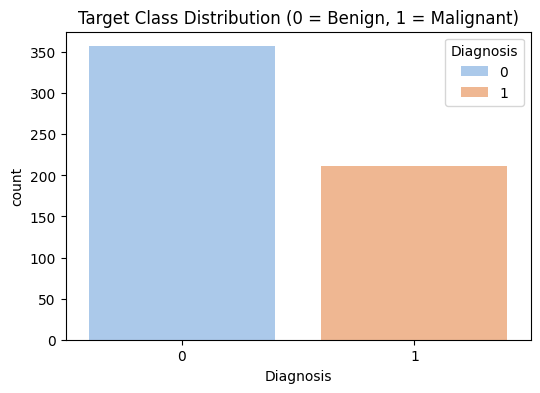

In [22]:
# Visualize class distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Diagnosis', hue='Diagnosis', palette='pastel')
plt.title('Target Class Distribution (0 = Benign, 1 = Malignant)')
plt.show()

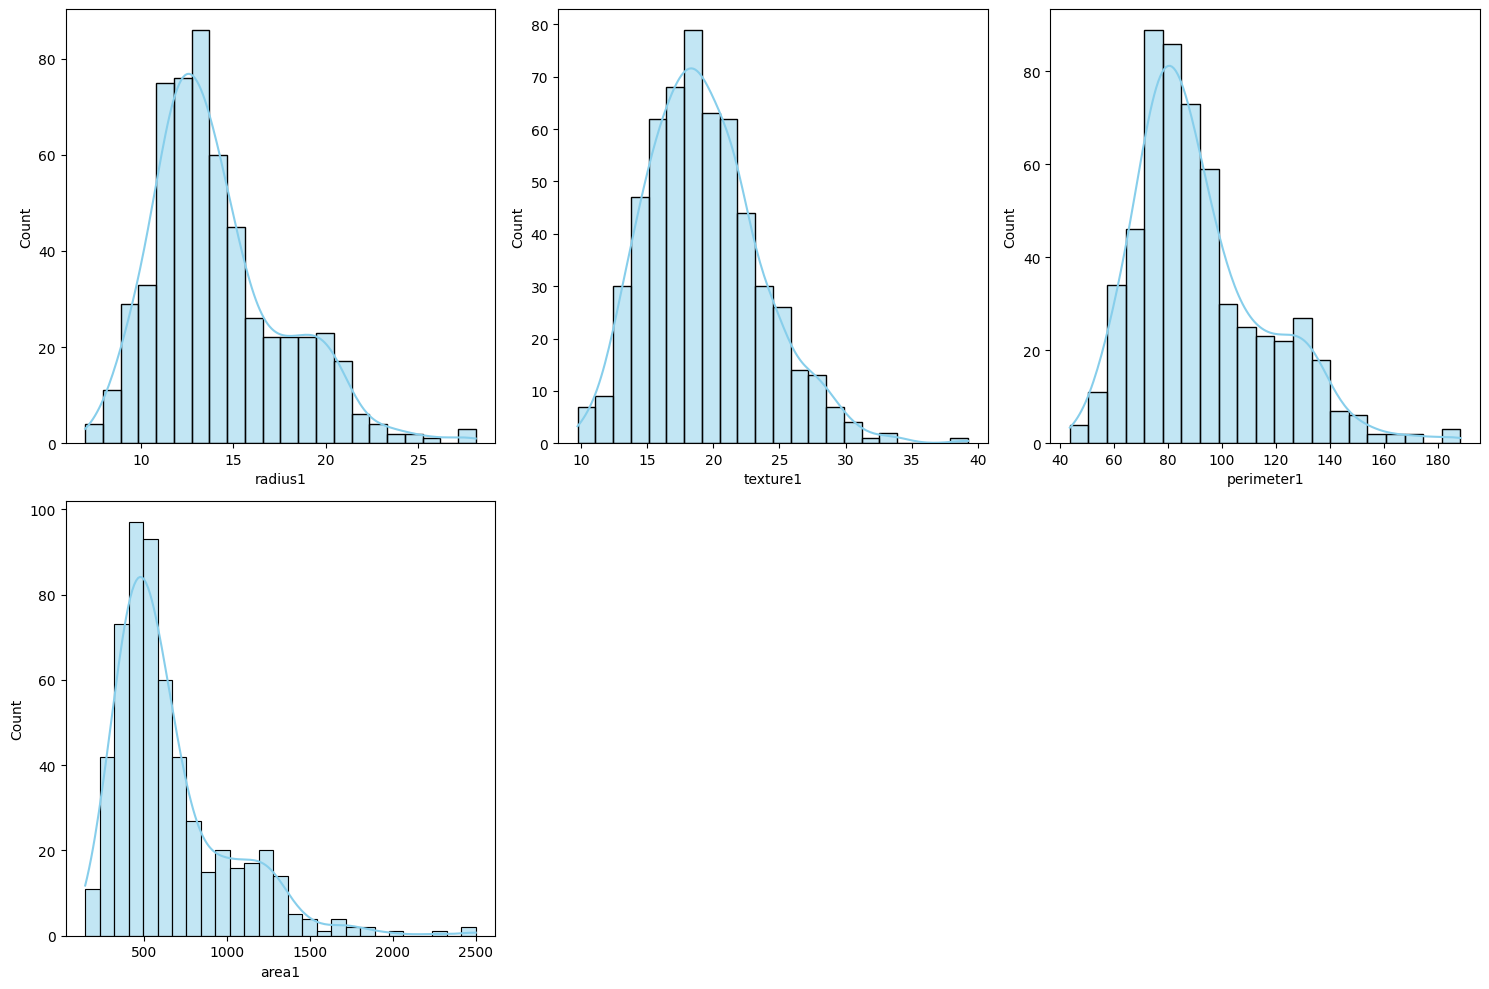

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

features_for_hist = ['radius1', 'texture1', 'perimeter1', 'area1']

fig = plt.figure(figsize=(15, 10))

for i, col in enumerate(features_for_hist):
    sub = fig.add_subplot(2, 3, i + 1)
    sub.set_xlabel(col)
    sns.histplot(data=df, x=df[col], kde=True, color='skyblue')

plt.tight_layout()
plt.show()

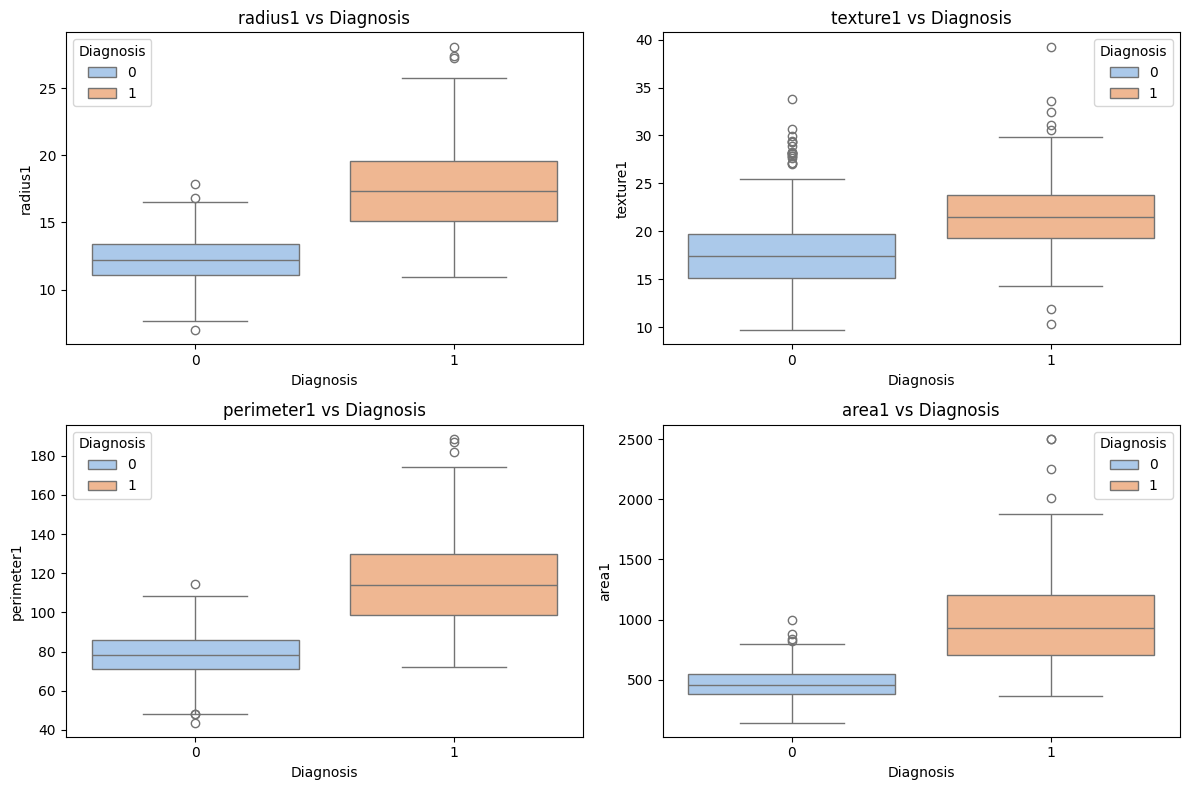

In [24]:
# Select the first four continuous features to visualize
features_to_plot = ['radius1', 'texture1', 'perimeter1', 'area1']
fig = plt.figure(figsize=(12, 8))

for i in range(len(features_to_plot)):
    sub = fig.add_subplot(2, 2, i+1)
    # Using seaborn's boxplot visualization
    sns.boxplot(x='Diagnosis', y=features_to_plot[i], data=df, palette='pastel', hue='Diagnosis')
    sub.set_title(f'{features_to_plot[i]} vs Diagnosis')

plt.tight_layout()
plt.show()

Interpretations:

I used the count plot to evaluate the clas distribution and found out that there is a slight imbalance (slight more benign 0 than maligant 1). Since the dataset contain 30 features, its not practical to plot them all out, and I used a representative subset of the primary "mean" features (such as radius, texture, perimeter, and area) for box plot and histograms. It is revealed that feature like radius1 and area1 show dinstinct seperation in mdeian values between the two classes and they will serve as strong predictors for the classification model.

In [25]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Split the dataset into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: X={X_train.shape}, y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, y={y_test.shape}")

# Initialize and train the baseline Logistic Regression model
baseline_model = LogisticRegression(max_iter=10000)
baseline_model.fit(X_train, y_train)

Training data shape: X=(455, 30), y=(455,)
Test data shape: X=(114, 30), y=(114,)


LogisticRegression(max_iter=10000)

In [26]:
# Predict on the test set
y_pred = baseline_model.predict(X_test)

# Calculate and print the performance metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Baseline Model Performance:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

Baseline Model Performance:
Accuracy:  0.9561
Precision: 0.9750
Recall:    0.9070
F1 Score:  0.9398


Baseline Model Evaluation:

Although a strong overall accuracy of 95.61%, along with a high precision of 97.50% is acheived, its recall score is at 90.70% (not yet ideal). For breast cancer diagnosis, we want to maximize recall because a false negative (failing to identify an actual malignant tumor) is much worse than a false positive. To improve this baseline model, we must apply feature selection to remove noisy or redundant variables and utilize hyperparameter tuning (such as adjusting class weights or regularization) to penalize false negatives more heavily.

In [27]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Build a pipeline with a Scaler, Feature Selection, and the Alternative Model
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('feature_selection', SelectKBest(score_func=f_classif, k=15)), # Select top 15 features
    ('classifier', RandomForestClassifier(random_state=42))
])

# 2. Define hyperparameters to tune
param_grid = {
    'classifier__n_estimators': [50, 100, 200],
    'classifier__max_depth': [None, 5, 10],
    'classifier__class_weight': ['balanced', 'balanced_subsample'] # Helps improve recall
}

# 3. Set up GridSearchCV to find the best combination, prioritizing Recall
grid_search = GridSearchCV(pipeline, param_grid, cv=5, scoring='recall')
grid_search.fit(X_train, y_train)

# 4. Extract the best model and evaluate
best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)

print("Best Parameters:", grid_search.best_params_)
print("\nImproved Model Performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tuned):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}")
print(f"F1 Score:  {f1_score(y_test, y_pred_tuned):.4f}")

Best Parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 5, 'classifier__n_estimators': 200}

Improved Model Performance:
Accuracy:  0.9561
Precision: 0.9524
Recall:    0.9302
F1 Score:  0.9412


In this part I transition into a Random Forest Classifier, applied feature selection (SelectKBest) to reduce noise, and utilized GridSearchCV for hyperparameter tuning; which resulted the model's recall improvement from 90.70% to 93.02%. The grid search found out that the optimal parameters is a max depth of 5, 200 estimators, and balanced class weights. The result shows a meaningful inprovement for the medical diagonostic tool becasue its increase in recall means it reduce the likelyhood of fase negaties (while not sacraficing the acurracy as much).

Disclaimer:

I made use of AI to help me in this project. It help me refine my text, validate my coding, and helped me double check the solution I produced. I have upload to AI to check my work. AI also given me the suggetion on what feature (out of 30 provided) to be used. It also help me write the entire README Report that I uploaded onto Github. It now looks a lot more professional than my personal writting.